# A solar panel on a cool spring morning, explained simply

Sheet: *Apl. 3.3*, questions (a) to (e) on a solar panel.

# Part 0: What a solar panel does

> **Photovoltaic (PV) cell**: a thin slice of silicon that turns light directly into electricity. It is a tiny battery that only works while light falls on it.

![Inside one PV cell: light frees an electron, the boundary between the two silicon layers pushes it out through the front fingers, and it returns through the load to the back contact](images/pv-cell.svg)

*Figure: Inside one PV cell: light frees an electron, the boundary between the two silicon layers pushes it out through the front fingers, and it returns through the load to the back contact*

> **PV module** (solar panel): many cells wired one after the other inside a frame, so that their small voltages add up. The module of the sheet is the Kyocera KD230GX-LPB (a model name, made by the company Kyocera).

![A PV module: about 60 cells in a snake-like series string, the output cables in the junction box, and the layers of the module seen from the side](images/pv-module.svg)

*Figure: A PV module: about 60 cells in a snake-like series string, the output cables in the junction box, and the layers of the module seen from the side*

> **Direct current (DC)**: electricity that flows steadily in one direction, like the current of a battery. A solar panel produces DC.

Electricity is easiest to picture as water in a pipe:

> **Voltage** $U$ (volt, V): the push behind the electricity, like the height of a waterfall.

> **Current** $I$ (ampere, A): how much electricity flows each second, like the amount of water flowing.

> **Power** $P$ (watt, W): how much work the electricity does each second, push times flow: $P = U \cdot I$.

> **Solar irradiance** $G$ (W/m²): the power of the sunlight landing on one square metre. It is the "rain intensity" of the sun: strong at a clear noon (about 1000 W/m²), weaker in the morning or under clouds.

![From sunlight to electricity: the sun shines on a cell, many cells form a module and the module delivers voltage, current and power](images/pv-chain.svg)

*Figure: From sunlight to electricity: the sun shines on a cell, many cells form a module and the module delivers voltage, current and power*

> **Standard test conditions (STC)**: the laboratory test every panel is rated with: $G = 1000$ W/m² and cells at 25 °C. It is the "fuel consumption in the brochure" of solar panels.

> **Rated power** $P_{M,st}$: the power the panel gives under STC. For this module it is 230 W, like the top speed in a car brochure: real days rarely match it.

A real day differs from the test in two ways: the sun is weaker or stronger, and the cells are warmer or colder. The exercise asks how much these two differences cost on a cool, clear spring morning.

# Part 1 (a): How hot is the cell?

**Idea.** Sunlight that is not turned into electricity warms the panel, like a dark car roof in the sun. So the cells are always warmer than the air around them, and the stronger the sun, the bigger the gap.

> **Air temperature** $t_a$ (°C): the temperature of the surrounding air. On the spring morning it is 12 °C.

> **Cell temperature** $t_c$ (°C): the temperature of the cells themselves. This is the one that decides how well the panel works.

> **NOCT** (nominal operating cell temperature, °C): the cell temperature the maker measures with 800 W/m² of sunlight, 20 °C air and a light breeze. For this module it is 45 °C, so at 800 W/m² the cells are 25 °C hotter than the air.

**Recipe.**
1. Work out how much the sun heats the panel per unit of sunlight: (NOCT − 20) / 800 = 0.03125 °C for each W/m².
2. Multiply by the irradiance $G$ and add the air temperature: $t_c = t_a + 0.03125 \cdot G$.

In [1]:
import sys; sys.path.insert(0, "../../shared")
import numpy as np, matplotlib.pyplot as plt
from pv_module import *

plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.grid": True, "grid.alpha": .3})

In [2]:
morning = operating_point(G_MORNING, TA_MORNING)
noon = operating_point(G_NOON, TA_NOON)

In [3]:
print(f"Cell temperature on the spring morning: {morning['tc']:.1f} °C  ({morning['tc'] - TA_MORNING:.1f} °C above the air)")
print(f"Cell temperature at the hot noon:       {noon['tc']:.1f} °C  ({noon['tc'] - TA_NOON:.1f} °C above the air)")

Cell temperature on the spring morning: 27.6 °C  (15.6 °C above the air)
Cell temperature at the hot noon:       58.1 °C  (28.1 °C above the air)


![Cell temperature = air temperature + heating by the sun, for the spring morning and the hot noon](images/noct-rise.svg)

*Figure: Cell temperature = air temperature + heating by the sun, for the spring morning and the hot noon*

**What this means.**
* On the spring morning the cells reach **27.6 °C**, only 15.6 °C above the 12 °C air, and just 2.6 °C above the 25 °C of the STC test. The cells are almost at test temperature.
* At the hot noon the cells reach **58.1 °C**: 28.1 °C of sun heating on top of a 30 °C day.

> **Wind speed** $w$ (m/s): how fast the air moves. The exercise gives $w = 3$ m/s, but the NOCT model has no wind term, so it plays no part in the calculation. Real wind cools a panel, so the model slightly overestimates the cell temperature on a windy day. The wind is given as part of the weather description only.

# Part 2 (b): How much current and voltage?

**Idea.** The current follows the sunlight almost proportionally: half the sun, half the current. The voltage hardly cares about the sunlight but drops when the cells get hot.

> **Short-circuit current** $I_{sc}$ (A): the current when the two wires of the panel are joined directly. It is the largest current the panel can give, like a stream flowing freely with nothing holding it back. Under STC it is 8.36 A.

> **Photocurrent** $I_L$ (A): the current created by the light inside the cells. In this simple model it is equal to $I_{sc}$.

> **Open-circuit voltage** $U_0$ (V): the voltage when nothing is connected and no current flows. It is the largest push the panel can give. Under STC it is 36.9 V.

> **Temperature coefficient** $\mu$: how much a quantity changes for each degree of cell temperature. The current grows by 0.06 % per °C (almost no change), the voltage falls by 0.36 % per °C, six times more.

> **Reference temperature** $t_{c,st}$: the cell temperature at which the STC values are valid, 25 °C. The coefficients count the degrees **above 25 °C**, never above 0 °C.

**Recipe.**
1. Current: scale the STC current by the sunlight, $G / 1000$, with the tiny temperature correction.
2. Voltage: take the STC voltage and subtract 0.36 % for every degree the cell is above 25 °C.

In [4]:
print(f"Spring morning:  I_L = {morning['i_l']:.2f} A (STC {ISC_ST} A),  U_0 = {morning['u0']:.2f} V (STC {U0_ST} V)")
print(f"Hot noon:        I_L = {noon['i_l']:.2f} A,  U_0 = {noon['u0']:.2f} V")

Spring morning:  I_L = 4.19 A (STC 8.36 A),  U_0 = 36.55 V (STC 36.9 V)
Hot noon:        I_L = 7.67 A,  U_0 = 32.50 V


**What this means.**
* The current is **4.19 A**, almost exactly half of 8.36 A: the sun is at half strength. The cell warmth adds a negligible 0.16 %.
* The voltage is **36.55 V**: only 0.35 V (about 1 %) below the STC value, because the cells are just 2.6 °C above the reference.
* At the hot noon the current is much higher (7.67 A) but the hot cells lose 12 % of their voltage (32.50 V).

# Part 3 (c): How much power?

**Idea.** Voltage times current would be the ideal power, but the panel cannot give both at their maximum at the same time. When the wires are joined the current is large and the voltage is zero; when nothing is connected the voltage is large and the current is zero. In between there is a sweet spot.

> **Current-voltage (I-V) curve**: the graph of the current the panel gives at each voltage. It starts at $I_{sc}$ with zero voltage and falls to zero current at $U_0$.

> **Maximum power point (MPP)**: the spot on the I-V curve where voltage times current is the largest. Electronics connected to a panel keep it working there.

![The power electronics between the module and the grid: the MPP tracker keeps the module at its maximum power point and the inverter turns its DC into AC](images/mpp-tracker.svg)

*Figure: The power electronics between the module and the grid: the MPP tracker keeps the module at its maximum power point and the inverter turns its DC into AC*

> **Maximum power** $P_M$ (W): the power at the MPP, the number that counts.

> **Fill factor** FF: how close the curve is to a perfect rectangle, in other words the share of the ideal $U_0 \cdot I_{sc}$ that the panel really delivers. FF = 0.746 means 74.6 %.

**Recipe.** Multiply three numbers: $P_M = FF \cdot U_0 \cdot I_{sc}$. The sheet keeps FF constant.

![The I-V curve at STC and on the spring morning: half the sunlight halves the current, the voltage barely moves](images/iv-curve.svg)

*Figure: The I-V curve at STC and on the spring morning: half the sunlight halves the current, the voltage barely moves*

In [5]:
print(f"Spring morning:  P_M = {morning['p_m']:.1f} W")
print(f"Hot noon:        P_M = {noon['p_m']:.1f} W")

Spring morning:  P_M = 114.2 W
Hot noon:        P_M = 186.0 W


**What this means.** On the spring morning the module delivers **114.2 W**, about the power of two ordinary light bulbs. That is roughly half of its 230 W rating, which matches the half-strength sun.

# Part 4 (d): Which condition gets closer to the rating?

> **Relative efficiency** (%): how much electricity the panel makes from the same amount of sunlight compared with the STC test. 100 % means as good as in the test; less means the heat is costing output.

**Recipe.** Divide the power by the 230 W rating to get the percentage. Compare it for both days.

In [6]:
print(f"Spring morning:  {morning['p_m']:.1f} W = {morning['percent_of_rated']:.1f} % of 230 W,  relative efficiency {relative_efficiency(morning['g'], morning['tc']):.1f} %")
print(f"Hot noon:        {noon['p_m']:.1f} W = {noon['percent_of_rated']:.1f} % of 230 W,  relative efficiency {relative_efficiency(noon['g'], noon['tc']):.1f} %")

Spring morning:  114.2 W = 49.6 % of 230 W,  relative efficiency 99.2 %
Hot noon:        186.0 W = 80.9 % of 230 W,  relative efficiency 89.8 %


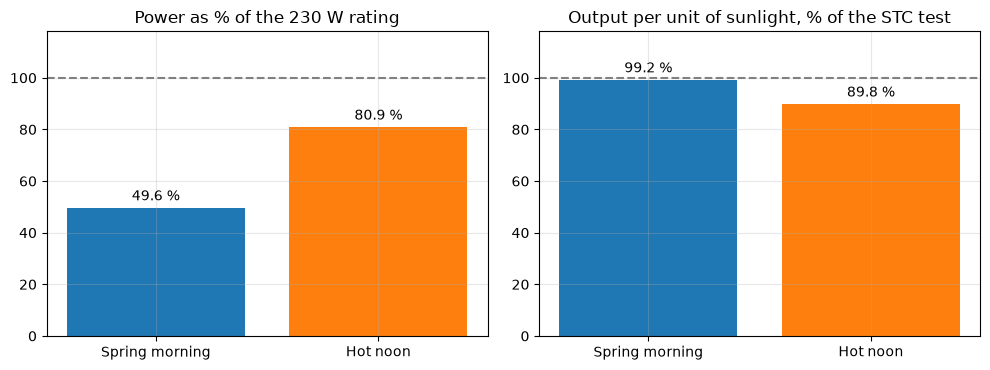

In [7]:
names = ["Spring morning", "Hot noon"]
cases = [morning, noon]
fig_, ax = plt.subplots(1, 2, figsize=(10, 3.8))
pct = [c["percent_of_rated"] for c in cases]
eff = [relative_efficiency(c["g"], c["tc"]) for c in cases]
for a_, vals, title in ((ax[0], pct, "Power as % of the 230 W rating"), (ax[1], eff, "Output per unit of sunlight, % of the STC test")):
    bars = a_.bar(names, vals, color=["tab:blue", "tab:orange"])
    a_.bar_label(bars, fmt="%.1f %%", padding=3)
    a_.axhline(100, ls="--", color="gray")
    a_.set(title=title, ylim=(0, 118))
plt.tight_layout(); plt.show()

*Figure: Left, the power as a share of the rating: the hot noon is closer. Right, the output per unit of sunlight: the spring morning is closer to the test.*

**What this means.**
* The **hot noon gets closer to the rating: 80.9 %** (the sheet's "about 80 %") against **49.6 %** on the spring morning.
* The reason is the sunlight: 900 W/m² is almost the test sunlight, 500 W/m² is only half. Power follows the sun.
* The cell temperature goes the other way. The cool morning panel is as efficient as in the test (99.2 %), while the hot noon panel loses about 10 % to heat (89.8 %). Like an athlete: cool weather is better for performance, but the morning has fewer chances to play.

# Part 5 (e): How much of the drop is the sun and how much is the heat?

Under STC the model gives 230.1 W (the 230 W on the label is rounded). The spring morning gives 114.2 W, a drop of 116.0 W.

> **Irradiance effect**: the power lost because the sunlight is weaker, with the cell kept at 25 °C.

> **Temperature effect**: the power lost because the cell is not at 25 °C, counted on top of the irradiance effect.

**Recipe.** First lower the sunlight and keep the cell at 25 °C: that is the irradiance effect. What is still missing to reach the final power is the temperature effect. Doing it in the opposite order (heat first, then dim) gives slightly different shares, because the two effects multiply; both are shown.

In [8]:
for name, (g, ta) in (("Spring morning", (G_MORNING, TA_MORNING)), ("Hot noon", (G_NOON, TA_NOON))):
    s = loss_split(g, ta)
    a, b = s["irradiance_first"], s["temperature_first"]
    print(f"{name}: drop {s['drop']:.1f} W")
    print(f"   sunlight first : sunlight {a['irradiance']:.1f} W + heat {a['temperature']:.1f} W")
    print(f"   heat first     : heat {b['temperature']:.1f} W + sunlight {b['irradiance']:.1f} W")

Spring morning: drop 116.0 W
   sunlight first : sunlight 115.1 W + heat 0.9 W
   heat first     : heat 1.8 W + sunlight 114.2 W
Hot noon: drop 44.1 W
   sunlight first : sunlight 23.0 W + heat 21.1 W
   heat first     : heat 23.4 W + sunlight 20.7 W


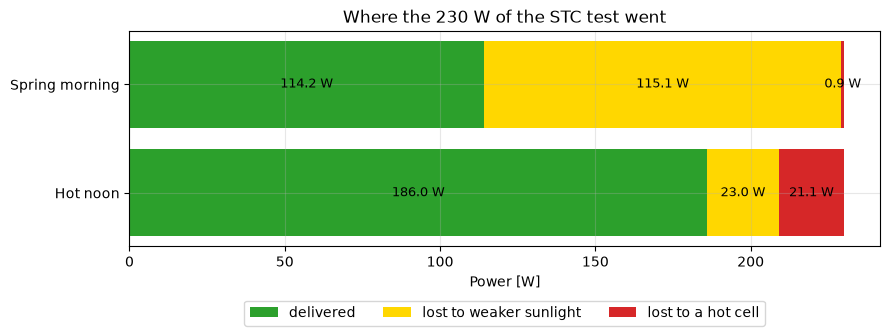

In [9]:
fig_, ax = plt.subplots(figsize=(9, 3.6))
for i, (name, (g, ta)) in enumerate((("Spring morning", (G_MORNING, TA_MORNING)), ("Hot noon", (G_NOON, TA_NOON)))):
    s = loss_split(g, ta)
    parts = [s["p_m"], s["irradiance_first"]["irradiance"], s["irradiance_first"]["temperature"]]
    left = 0
    for part, color, label in zip(parts, ("tab:green", "gold", "tab:red"), ("delivered", "lost to weaker sunlight", "lost to a hot cell")):
        ax.barh(i, part, left=left, color=color, label=label if i == 0 else None)
        ax.text(left + part / 2, i, f"{part:.1f} W", ha="center", va="center", fontsize=9)
        left += part
ax.set(yticks=[0, 1], yticklabels=["Spring morning", "Hot noon"], xlabel="Power [W]", title="Where the 230 W of the STC test went")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3); ax.invert_yaxis(); plt.tight_layout(); plt.show()

*Figure: Where the 230 W of the STC test went on the two days (sunlight first)*

**What this means.**
* On the spring morning almost the whole drop is the weaker sun: **about 115 W of the 116 W**. The heat costs only **0.9 to 1.8 W** (under 1 % of the rating), because the cells are barely above 25 °C.
* At the hot noon the sunlight costs only about 21 to 23 W, and the **hot cells cost about the same, 21 to 23 W**. Heat matters when the day is hot, not when it is cool.

# Summary of the answers

* **(a)** $t_c = 27.6$ °C.
* **(b)** $I_L = I_{sc} = 4.19$ A and $U_0 = 36.55$ V.
* **(c)** $P_M = 114.2$ W.
* **(d)** 49.6 % of the rating, against about 81 % at the hot noon: the hot noon is closer, because of the stronger sun.
* **(e)** About 115 W of the 116 W drop comes from the weaker sunlight, about 1 W from the cell temperature.